# 02. Klasifikasi URL — KNN + Fitur Numerik Buatan Sendiri (Versi Pribadi / VP)

Saudara kembar `01_KNN_TFIDF_VP` — dibangun **dari nol** sebagai eksperimen pribadi,
**tidak** mengikuti protokol notebook kelompok. Dataset sama:
`Malicious URL Detection (1).csv` (783.705 URL, 7 kelas: benign, defacement, exploit,
legitimate, malware, phishing, spam).

Kalau 01_VP memakai filosofi "biarkan data berbicara" (TF-IDF otomatis), versi ini
memakai filosofi kedua: **feature engineering** — manusia yang merancang ciri-ciri
numerik dari teks dan struktur URL.

**Keputusan desain versi ini** (alasannya dijelaskan di tiap bagian):

1. **Pembersihan:** sama dengan 01_VP — buang baris kosong, URL berlabel konflik, dan duplikat exact.
2. **Seluruh 783.702 baris bersih dipakai** (tanpa sampling).
3. **Split 70/15/15** (train/validation/test), acak stratified, **seed & resep sama
   dengan 01_VP** — sehingga partisi kedua notebook VP identik dan hasilnya bisa
   dibandingkan secara adil.
4. **Fitur: 37 fitur numerik rancangan sendiri** (panjang komponen, komposisi karakter,
   struktur hostname, struktur URL, pola kata mencurigakan, kondisi parsing)
   + **StandardScaler** yang di-fit hanya pada train.
5. **Model: KNN** jarak **euclidean** (pilihan standar untuk data numerik padat —
   berbeda dari 01_VP yang memakai cosine untuk teks sparse); `k` di-sweep di validation.
6. **Metrik utama: macro F1** + **bonus analisis feature importance** — keunggulan
   utama feature engineering: hasilnya bisa diinterpretasi.

**Waktu jalan:** jauh lebih ringan daripada 01_VP — hanya 37 fitur (vs 50.000) dan
matriksnya padat, sehingga jarak euclidean dihitung lewat aljabar matriks (BLAS)
yang sangat cepat. Perkiraan: **hitungan menit**, bukan jam.

## 0. Feature engineering itu apa? (ringkasan konsep)

Model hanya mengerti **angka**; URL adalah teks — jadi butuh "penerjemah". Ada dua filosofi:

- **TF-IDF (01_VP):** penerjemah *otomatis* — pola dipelajari dari seluruh dataset;
  hasilnya puluhan ribu angka yang sulit dibaca manusia.
- **Feature engineering (notebook ini):** penerjemah *manual* — **manusia** yang
  memutuskan ciri apa yang diukur, berdasarkan pengetahuan "URL jahat itu biasanya
  seperti apa"; hasilnya sedikit angka yang artinya jelas.

Analogi: menilai sebuah surat penipuan. TF-IDF membandingkan gaya seluruh potongan
katanya dengan surat-surat lain. Feature engineering langsung mengisi **checklist**:
*alamat pengirimnya angka acak? banyak kata mendesak? tautannya menyamar?* — setiap
poin checklist adalah satu **fitur**.

**Kenapa KNN butuh tahap ekstra di jalur ini?** Skala antar fitur beda jauh:
panjang URL bernilai ratusan, `has_port` hanya 0/1. Tanpa disetarakan, fitur "panjang"
mendominasi perhitungan jarak dan fitur lain nyaris tak terdengar. Karena itu ada
**StandardScaler**: setiap fitur dikurangi rata-ratanya lalu dibagi simpangan bakunya
→ semua fitur berskala setara, semua dapat "suara" yang adil. (Rata-rata & simpangan
baku **hanya dipelajari dari train** — validation/test cuma ikut aturan train.)

In [1]:
from pathlib import Path
import json
import math
import re
import sys
import time
import ipaddress
import importlib.metadata
from collections import Counter
from urllib.parse import urlsplit
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ---------- konstanta eksperimen (silakan ubah di sini) ----------
SEED = 42
SPLIT_TEST = 0.30             # 30% dibagi lagi jadi validation & test -> 70/15/15
METRIC = "euclidean"          # jarak KNN; boleh dicoba "cosine" sebagai pembanding
K_CANDIDATES = [3, 5, 7, 9]   # kandidat jumlah tetangga untuk sweep di validation

DATA_CANDIDATES = [
    Path("../dataset/Malicious URL Detection (1).csv"),
    Path("Malicious URL Detection (1).csv"),
]
DATA_FILE = next((p for p in DATA_CANDIDATES if p.exists()), DATA_CANDIDATES[0])
RESULTS_DIR = Path("results_vp")
RESULTS_DIR.mkdir(exist_ok=True)

print("Python  :", sys.executable)
print("Dataset :", DATA_FILE.resolve())
versi = {n: importlib.metadata.version(n)
         for n in ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib"]}
display(pd.Series(versi, name="versi").to_frame())

Python  : d:\Semester5\ML\244107020017_Machine_Learning\PBL\Exsperimen\.venv\Scripts\python.exe
Dataset : D:\Semester5\ML\244107020017_Machine_Learning\PBL\dataset\Malicious URL Detection (1).csv


,versi
numpy,2.5.4
pandas,3.1.0
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2


## 1. Muat dan bersihkan data

**Tujuan:** memastikan data layak pakai sebelum diukur fitur apa pun.
(Langkahnya identik dengan 01_VP — supaya perbandingan kedua notebook adil.)

- CSV dibaca sebagai **teks mentah** (semua kolom string) supaya tidak ada nilai yang
  diam-diam diubah pandas menjadi NaN/angka.
- Spasi di ujung URL dibuang; label diseragamkan jadi huruf kecil.
- **Baris kosong** (URL atau label kosong) dibuang.
- **URL dengan label bertentangan** (URL sama tapi kelasnya beda) dibuang — datanya
  ambigu, model tidak bisa belajar dari kontradiksi.
- **Duplikat exact dibuang.** Karena split kita acak, duplikat yang tersisa bisa
  mendarat di train *dan* test sekaligus — model tinggal "menyalin jawaban"
  (kebocoran halus). Semua angka perubahan dicatat, tidak ada yang diam-diam.

In [2]:
if not DATA_FILE.exists():
    raise FileNotFoundError(f"Dataset tidak ditemukan: {DATA_FILE.resolve()}")

raw = pd.read_csv(DATA_FILE, dtype=str, keep_default_na=False)
if not {"url", "type"} <= set(raw.columns):
    raise ValueError(f"Kolom dataset tidak sesuai: {raw.columns.tolist()}")
print(f"Baris mentah: {len(raw):,} | kolom: {raw.columns.tolist()}")

df = pd.DataFrame({
    "url": raw["url"].str.strip(),
    "label": raw["type"].str.strip().str.lower(),
})

# 1) buang baris dengan url/label kosong
n_kosong = int(((df.url == "") | (df.label == "")).sum())
df = df[(df.url != "") & (df.label != "")]

# 2) buang URL yang labellnya bertentangan (konservatif: seluruh URL-nya dibuang)
nunique = df.groupby("url")["label"].nunique()
url_konflik = set(nunique[nunique > 1].index)
df = df[~df.url.isin(url_konflik)]

# 3) buang duplikat exact, simpan kemunculan pertama
n_dup = int(df.duplicated(subset="url").sum())
df = df.drop_duplicates(subset="url", keep="first").reset_index(drop=True)

print(f"Baris kosong dibuang            : {n_kosong}")
print(f"URL berlabel konflik dibuang    : {len(url_konflik)}")
print(f"Duplikat exact dibuang          : {n_dup}")
print(f"Baris bersih                    : {len(df):,}")
print(f"Kelas                           : {sorted(df.label.unique())}")
df.head()

Baris mentah: 783,705 | kolom: ['url', 'type']
Baris kosong dibuang            : 0
URL berlabel konflik dibuang    : 0
Duplikat exact dibuang          : 3
Baris bersih                    : 783,702
Kelas                           : ['benign', 'defacement', 'exploit', 'legitimate', 'malware', 'phishing', 'spam']


,url,label
0,mp3raid.com/music/krizz_kaliko.html,benign
1,bopsecrets.org/rexroth/cr/1.htm,benign
2,buzzfil.net/m/show-art/ils-etaient-loin-de-s-i...,benign
3,espn.go.com/nba/player/_/id/3457/brandon-rush,benign
4,yourbittorrent.com/?q=anthony-hamilton-soulife,benign


## 2. EDA ringan: distribusi kelas

Sebelum lanjut, lihat dulu "medan perangnya". Dataset ini **sangat timpang**:
`benign` separuh lebih, sedangkan `exploit` cuma 243 baris dari 783 ribu.

Konsekuensinya:

- Model pemalas bisa dapat accuracy ~54% hanya dengan menebak `benign` terus.
  Karena itu **accuracy bukan metrik utama** di sini — kita utamakan **macro F1**
  (rata-rata F1 semua kelas dengan bobot sama, sehingga kegagalan di kelas langka
  langsung terlihat).
- Split nanti harus **stratified** supaya komposisi kelas di train/validation/test
  tetap sama dengan aslinya.
- Grafik pakai skala log — kalau tidak, batang kelas kecil tidak akan kelihatan.

,jumlah,persen
label,,
benign,426432,54.4125
defacement,95263,12.1555
exploit,243,0.0310
legitimate,5809,0.7412
malware,23592,3.0103
phishing,229610,29.2981
spam,2753,0.3513


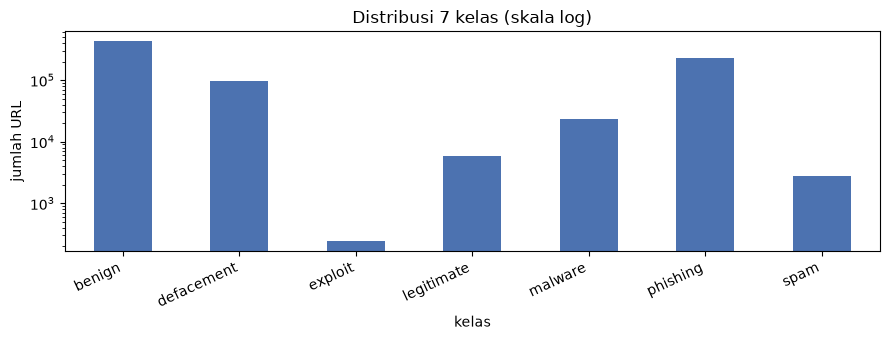

Kelas terbesar  : benign (54.41%)
Kelas terkecil  : exploit (0.0310%)


In [3]:
counts = df.label.value_counts().sort_index()
dist = pd.DataFrame({"jumlah": counts,
                     "persen": (counts / len(df) * 100).round(4)})
display(dist)

fig, ax = plt.subplots(figsize=(9, 3.5))
counts.plot.bar(ax=ax, color="#4c72b0")
ax.set(title="Distribusi 7 kelas (skala log)", xlabel="kelas", ylabel="jumlah URL")
ax.set_yscale("log")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

print(f"Kelas terbesar  : {counts.idxmax()} ({counts.max() / len(df):.2%})")
print(f"Kelas terkecil  : {counts.idxmin()} ({counts.min() / len(df):.4%})")

## 3. Feature engineering: 37 fitur numerik rancangan sendiri

Setiap URL "diukur" dengan 37 penggaris, dikelompokkan dalam 6 keluarga:

| Kelompok | Contoh fitur | Intuisi kenapa berguna |
|---|---|---|
| A. Panjang komponen (5) | `url_len`, `host_len`, `path_len`, `query_len`, `fragment_len` | URL phishing sering panjang (subdomain peniru + parameter pengecoh) |
| B. Komposisi karakter (7) | `digit_ratio`, `upper_ratio`, `unique_char_ratio`, `char_entropy` | alamat acak/acak-acakan (entropi tinggi) khas domain jahat |
| C. Struktur hostname (6) | `host_dot_count`, `host_hyphen_count`, `host_is_ip`, `host_is_punycode` | banyak subdomain/hyphen, IP mentah, punycode `xn--` = trik penyamaran |
| D. Struktur URL (8) | `has_https`, `has_port`, `has_userinfo`, `path_depth`, `query_param_count` | port aneh, tanda `@`, path sangat dalam = tanda mencurigakan |
| E. Pola mencurigakan (9) | `kw_login`, `kw_verify`, `kw_bank`, ..., `percent_escape_count`, `double_slash_count` | kata klasik halaman peniru login; `%XX` dan `//` untuk obfuscation |
| F. Kondisi parsing (2) | `parse_failed`, `hostname_missing` | URL rusak/tak bisa diurai adalah sinyal merah tersendiri |

**Kenapa langkah ini tidak bocor?** Ekstraksinya 100% **deterministik** — fitur sebuah
URL dihitung hanya dari teks URL itu sendiri; tidak ada statistik yang dipelajari dari
baris lain, dan label tidak diintip. Bagian yang *belajar dari data* baru muncul nanti
(StandardScaler), dan itu **di-fit hanya pada train**.

URL yang rusak **tidak dibuang** — dia tetap dipakai dan diberi tanda `parse_failed=1`.
Membuang baris justru menghilangkan informasi dan membuat bias.

In [4]:
SKEMA = re.compile(r"^[a-z][a-z0-9+.-]*://")
PERSEN = re.compile(r"%[0-9a-fA-F]{2}")


def ekstrak_fitur(url):
    # Ukur satu URL dengan 37 penggaris. Deterministik: hanya bergantung teks URL.
    s = str(url)
    rendah = s.lower()

    # --- parsing URL (tanpa skema -> beri prefiks "//" agar hostname terbaca) ---
    try:
        parsed = urlsplit(s if (SKEMA.match(rendah) or s.startswith("//")) else "//" + s)
        host = (parsed.hostname or "").lower().rstrip(".")
        path, query, frag = parsed.path, parsed.query, parsed.fragment
        userinfo = int("@" in (parsed.netloc or ""))
        gagal = 0
    except ValueError:
        parsed, host, path, query, frag = None, "", s, "", ""
        userinfo, gagal = 0, 1
    try:
        ada_port = int(parsed is not None and parsed.port is not None)
    except ValueError:
        ada_port = 0                      # port ditulis tidak valid (mis. ":abc")
    try:
        ipaddress.ip_address(host)
        host_ip = 1
    except ValueError:
        host_ip = 0

    # --- statistik karakter ---
    hitung = Counter(s)
    L = max(len(s), 1)
    n_digit = sum(c for ch, c in hitung.items() if ch.isdigit())
    n_huruf = sum(c for ch, c in hitung.items() if ch.isalpha())
    n_kapital = sum(c for ch, c in hitung.items() if ch.isupper())
    entropi = -sum((c / L) * math.log2(c / L) for c in hitung.values())
    label_host = host.split(".") if host else []

    return {
        # A. panjang komponen (5)
        "url_len": len(s), "host_len": len(host), "path_len": len(path),
        "query_len": len(query), "fragment_len": len(frag),
        # B. komposisi karakter (7)
        "digit_count": n_digit,
        "digit_ratio": n_digit / L,
        "letter_ratio": n_huruf / L,
        "upper_ratio": n_kapital / L,
        "special_ratio": (len(s) - n_digit - n_huruf) / L,
        "unique_char_ratio": len(hitung) / L,
        "char_entropy": entropi,
        # C. struktur hostname (6)
        "host_dot_count": host.count("."),
        "host_hyphen_count": host.count("-"),
        "host_digit_ratio": sum(ch.isdigit() for ch in host) / max(len(host), 1),
        "longest_host_label": max((len(p) for p in label_host), default=0),
        "host_is_ip": host_ip,
        "host_is_punycode": int("xn--" in host),
        # D. struktur URL (8)
        "has_scheme": int(bool(SKEMA.match(rendah))),
        "has_https": int(rendah.startswith("https://")),
        "has_port": ada_port,
        "has_query": int(bool(query)),
        "has_fragment": int(bool(frag)),
        "has_userinfo": userinfo,
        "path_depth": sum(1 for seg in path.split("/") if seg),
        "query_param_count": sum(1 for q in query.split("&") if q),
        # E. pola mencurigakan (9)
        "percent_escape_count": len(PERSEN.findall(s)),
        "double_slash_count": path.count("//"),
        "kw_login": rendah.count("login"),
        "kw_verify": rendah.count("verify"),
        "kw_secure": rendah.count("secure"),
        "kw_account": rendah.count("account"),
        "kw_update": rendah.count("update"),
        "kw_bank": rendah.count("bank"),
        "kw_free": rendah.count("free"),
        # F. kondisi parsing (2)
        "parse_failed": gagal,
        "hostname_missing": int(not host),
    }


# nama fitur = kunci dict dari satu URL contoh (urutan dict Python stabil)
NAMA_FITUR = list(ekstrak_fitur("http://contoh.com/login?a=1#x").keys())
print(f"Jumlah fitur rancangan: {len(NAMA_FITUR)}")

# ekstrak seluruh baris ke matriks numpy yang sudah dialokasikan (hemat memori)
t0 = time.perf_counter()
X_all = np.empty((len(df), len(NAMA_FITUR)), dtype=np.float64)
for i, u in enumerate(df.url.to_numpy()):
    X_all[i] = list(ekstrak_fitur(u).values())
    if (i + 1) % 200_000 == 0:
        print(f"  ... {i + 1:,}/{len(df):,} baris", flush=True)
assert np.isfinite(X_all).all(), "ada nilai NaN/inf — ekstraksi bermasalah"

feat_df = pd.concat([df.reset_index(drop=True),
                     pd.DataFrame(X_all, columns=NAMA_FITUR)], axis=1)
print(f"Ekstraksi selesai dalam {time.perf_counter() - t0:.1f} detik")
print("feat_df:", feat_df.shape, "(baris x [url + label + 37 fitur])")

# pratinjau: tiga URL "diukur" dengan seluruh fitur
display(feat_df.head(3).set_index("url").T)

Jumlah fitur rancangan: 37
  ... 200,000/783,702 baris
  ... 400,000/783,702 baris
  ... 600,000/783,702 baris
Ekstraksi selesai dalam 19.9 detik
feat_df: (783702, 39) (baris x [url + label + 37 fitur])


url,mp3raid.com/music/krizz_kaliko.html,bopsecrets.org/rexroth/cr/1.htm,buzzfil.net/m/show-art/ils-etaient-loin-de-s-imaginer-que-le-hibou-allait-faire-ceci-quand-ils-filmaient-2.html
label,benign,benign,benign
url_len,35.0,31.0,111.0
host_len,11.0,14.0,11.0
path_len,24.0,17.0,100.0
query_len,0.0,0.0,0.0
fragment_len,0.0,0.0,0.0
digit_count,1.0,1.0,1.0
digit_ratio,0.028571,0.032258,0.009009
letter_ratio,0.828571,0.806452,0.801802
upper_ratio,0.0,0.0,0.0


## 4. Split 70/15/15 atas SELURUH data (tanpa sampling) + StandardScaler

Seluruh **783.702 baris fitur** dibagi acak stratified: **train ±548 ribu**,
**validation ±117 ribu**, **test ±117 ribu**. Seed dan resepnya sama dengan 01_VP,
dan karena baris `df`-nya dibangun dengan langkah pembersihan yang identik,
**partisi kedua notebook VP benar-benar sama** — perbedaan skor nanti murni karena
representasi fiturnya, bukan karena pembagian datanya berbeda.

**Kenapa versi ini jauh lebih cepat dari 01_VP?** Biaya KNN kira-kira =
(jumlah baris yang diprediksi) × (jumlah baris train) × (jumlah fitur).

- 01_VP: ±117 ribu × ±548 ribu × **50.000** fitur sparse → jam-jaman.
- Versi ini: ±117 ribu × ±548 ribu × **37** fitur padat → jarak euclidean dihitung
  sebagai perkalian matriks oleh BLAS → **menit**.

Datanya sama persis; **representasi fitur yang menentukan biaya komputasi**.

Setelah split: **StandardScaler di-fit HANYA pada train**, lalu dipakai men-transform
validation/test. Ini prinsip anti-bocor yang sama dengan kosakata TF-IDF di 01_VP:
rata-rata & simpangan baku adalah "pengetahuan dari data" — tidak boleh ada yang
rembes dari validation/test.

⚠️ **Catatan kejujuran (limitasi vs protokol kelompok):** split di sini acak per-baris,
jadi domain yang sama *bisa* muncul di dua partisi (misal dua subdomain situs yang
sama). Protokol kelompok memakai split domain-disjoint untuk mencegah ini. Skor VP
karena itu bisa sedikit lebih optimis; itu konsekuensi desain yang kita sadari.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# split bertahap seluruh baris: 70% train, sisanya dibagi dua -> 15% val, 15% test
train_df, tmp_df = train_test_split(feat_df, test_size=SPLIT_TEST,
                                    stratify=feat_df.label, random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.5,
                                   stratify=tmp_df.label, random_state=SEED)

tabel = pd.DataFrame({
    "train": train_df.label.value_counts(),
    "validation": val_df.label.value_counts(),
    "test": test_df.label.value_counts(),
}).sort_index()
display(tabel)
print(f"train {len(train_df):,} | validation {len(val_df):,} | test {len(test_df):,}")

# sanity check: tidak ada URL yang sama menyeberang partisi (duplikat sudah dibuang)
assert len(set(train_df.url) & set(val_df.url)) == 0
assert len(set(train_df.url) & set(test_df.url)) == 0
assert len(set(val_df.url) & set(test_df.url)) == 0
print("OK: tidak ada URL identik yang menyeberang partisi.")

# StandardScaler: FIT hanya pada train; val/test hanya di-transform
t0 = time.perf_counter()
scaler = StandardScaler()
Xtr = scaler.fit_transform(train_df[NAMA_FITUR].to_numpy(dtype=np.float64))
Xva = scaler.transform(val_df[NAMA_FITUR].to_numpy(dtype=np.float64))
Xte = scaler.transform(test_df[NAMA_FITUR].to_numpy(dtype=np.float64))
y_train = train_df.label.to_numpy()
y_val = val_df.label.to_numpy()
y_test = test_df.label.to_numpy()
print(f"Scaling selesai dalam {time.perf_counter() - t0:.1f} detik")
print("Xtr:", Xtr.shape, "| Xva:", Xva.shape, "| Xte:", Xte.shape)
n_var_nol = int((scaler.var_ == 0).sum())
print(f"Fitur dengan varians nol di train: {n_var_nol} (skalanya otomatis diset 1)")

,train,validation,test
label,,,
benign,298502,63965,63965
defacement,66684,14289,14290
exploit,170,37,36
legitimate,4066,872,871
malware,16515,3538,3539
phishing,160727,34441,34442
spam,1927,413,413


train 548,591 | validation 117,555 | test 117,556
OK: tidak ada URL identik yang menyeberang partisi.
Scaling selesai dalam 0.3 detik
Xtr: (548591, 37) | Xva: (117555, 37) | Xte: (117556, 37)
Fitur dengan varians nol di train: 2 (skalanya otomatis diset 1)


## 5. Model: KNN + sweep nilai k di validation

KNN-nya sama seperti 01_VP — menyimpan seluruh data train, lalu memprediksi dengan
voting `k` tetangga terdekat (`weights="distance"`: tetangga lebih dekat = suara lebih
berat). Yang berbeda adalah **jarak**-nya:

- **01_VP (TF-IDF):** cosine — vektor teks sparse sudah L2-normalized; yang bermakna
  adalah *komposisi* pola, bukan besar-kecilnya vektor.
- **Versi ini (37 fitur numerik):** euclidean — fitur-fiturnya sudah disetarakan
  StandardScaler, sehingga jarak garis lurus = "selisih keseluruhan" antar URL.
  Ini pilihan textbook untuk data numerik padat. Mau menguji cosine? Ganti konstanta
  `METRIC` di sel paling atas — experimentation seperti itu tempatnya di validation,
  bukan test.

`algorithm="brute"` menghitung jarak ke semua baris train secara eksak (dengan 37
dimensi, BLAS menjadikannya perkalian matriks yang sangat cepat). `n_jobs=-1`
memparalelkan prediksi ke semua core CPU.

**Kenapa k di-sweep di validation, bukan test?** Supaya test tetap menjadi "ujian
nasional" yang dipakai sekali. `k` terlalu kecil → keputusan sensitif terhadap satu
tetangga (bisa noise); `k` terlalu besar → didominasi kelas mayoritas. Biarkan
validation yang memilih.

k=3: macro F1 validation = 0.6250  (73.6 detik)
k=5: macro F1 validation = 0.6407  (73.9 detik)
k=7: macro F1 validation = 0.6378  (73.1 detik)
k=9: macro F1 validation = 0.6352  (75.6 detik)


,k,macro_f1_val,detik
0,3,0.6250,73.6
1,5,0.6407,73.9
2,7,0.6378,73.1
3,9,0.6352,75.6


k terpilih (berdasarkan validation): 5


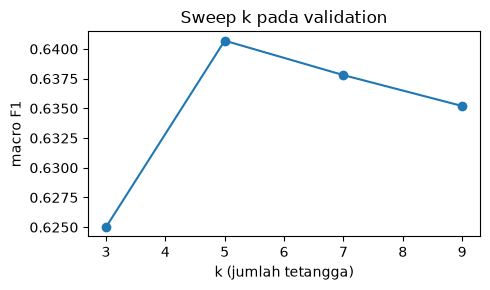

In [6]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score


def buat_knn(k):
    return KNeighborsClassifier(n_neighbors=k, weights="distance",
                                metric=METRIC, algorithm="brute", n_jobs=-1)


hasil_sweep = []
for k in K_CANDIDATES:
    knn = buat_knn(k)
    t0 = time.perf_counter()
    knn.fit(Xtr, y_train)              # fit KNN = sekadar menyimpan data (murah)
    pred_val = knn.predict(Xva)        # biaya: jarak ke semua baris train (cepat di versi ini)
    dt = time.perf_counter() - t0
    mf1 = f1_score(y_val, pred_val, average="macro", zero_division=0)
    hasil_sweep.append({"k": k, "macro_f1_val": round(float(mf1), 4),
                        "detik": round(dt, 1)})
    print(f"k={k}: macro F1 validation = {mf1:.4f}  ({dt:.1f} detik)", flush=True)

sweep = pd.DataFrame(hasil_sweep)
display(sweep)

K_TERBAIK = int(sweep.loc[sweep["macro_f1_val"].idxmax(), "k"])
print("k terpilih (berdasarkan validation):", K_TERBAIK)

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(sweep["k"], sweep["macro_f1_val"], marker="o")
ax.set(title="Sweep k pada validation", xlabel="k (jumlah tetangga)",
       ylabel="macro F1")
plt.tight_layout()
plt.show()

## 6. Evaluasi final pada test (dipakai sekali saja)

Model final: KNN dengan `k` terbaik dari sweep, dilatih ulang pada train, lalu
dinilai pada **test** yang belum pernah disentuh proses tuning apa pun.

**Cara membaca hasilnya:**

- **accuracy** — proporsi semua prediksi yang benar (bisa menipu di data timpang).
- **balanced accuracy** — rata-rata recall per kelas (lebih adil).
- **macro F1** ⭐ — rata-rata F1 semua kelas dengan bobot sama; metrik utama kita.
- **weighted F1** — seperti macro tapi mengikuti jumlah contoh per kelas.
- **classification report** — precision (dari yang diprediksi kelas X, berapa yang
  benar), recall (dari kelas X sebenarnya, berapa yang ketahuan), F1 (kombinasi),
  support (jumlah contoh).
- **confusion matrix** — baris = kelas sebenarnya, kolom = prediksi. Versi
  normalisasi-baris menunjukkan recall per kelas; sel diagonal = yang benar.

Prediksi 117,556 baris test dalam 72.8 detik


,test
accuracy,0.7956
balanced_accuracy,0.5959
macro_f1,0.6217
weighted_f1,0.7925


              precision    recall  f1-score   support

      benign       0.82      0.86      0.84     63965
  defacement       0.80      0.79      0.80     14290
     exploit       0.70      0.64      0.67        36
  legitimate       0.19      0.10      0.13       871
     malware       0.89      0.85      0.87      3539
    phishing       0.75      0.69      0.72     34442
        spam       0.54      0.23      0.32       413

    accuracy                           0.80    117556
   macro avg       0.67      0.60      0.62    117556
weighted avg       0.79      0.80      0.79    117556



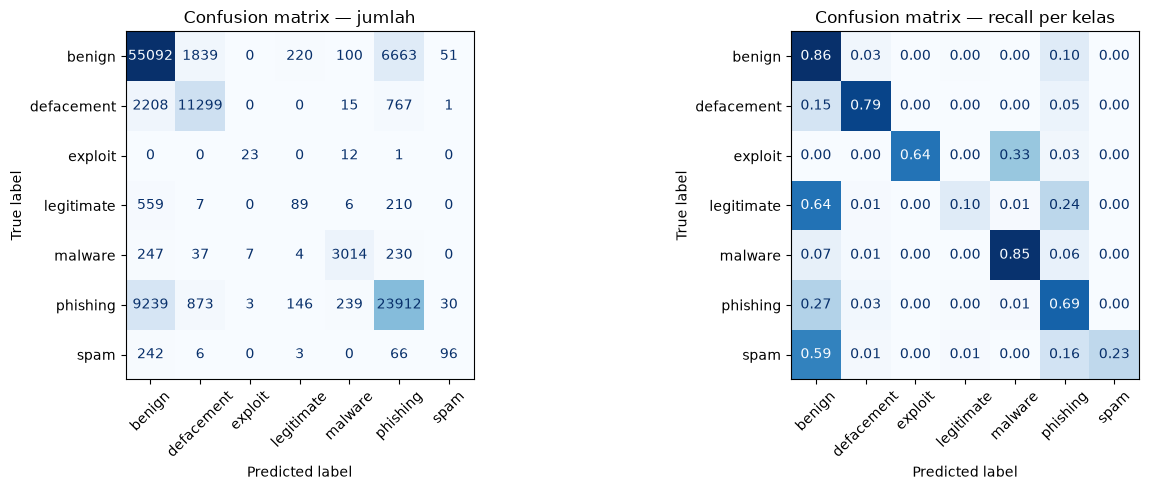

In [7]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

model_final = buat_knn(K_TERBAIK)
t0 = time.perf_counter()
model_final.fit(Xtr, y_train)
y_pred = model_final.predict(Xte)
print(f"Prediksi {Xte.shape[0]:,} baris test dalam {time.perf_counter() - t0:.1f} detik")

kelas = sorted(df.label.unique())
skor = {
    "accuracy": accuracy_score(y_test, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "macro_f1": f1_score(y_test, y_pred, labels=kelas, average="macro", zero_division=0),
    "weighted_f1": f1_score(y_test, y_pred, labels=kelas, average="weighted", zero_division=0),
}
display(pd.Series(skor, name="test").to_frame().round(4))
print(classification_report(y_test, y_pred, labels=kelas, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=kelas)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay(cm, display_labels=kelas).plot(
    ax=axes[0], cmap="Blues", colorbar=False, xticks_rotation=45, values_format="d")
axes[0].set_title("Confusion matrix — jumlah")
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=kelas).plot(
    ax=axes[1], cmap="Blues", colorbar=False, xticks_rotation=45, values_format=".2f")
axes[1].set_title("Confusion matrix — recall per kelas")
plt.tight_layout()
plt.show()

## 7. Bonus keunggulan feature engineering: fitur mana yang paling berperan?

Ini yang **tidak dimiliki** jalur TF-IDF: kita bisa mengintip ke dalam model.
**F-statistic (ANOVA)** mengukur seberapa besar nilai sebuah fitur *berbeda antar
7 kelas* — makin besar nilainya, makin kuat fitur itu memisahkan kelas. Perhitungan
hanya memakai data **train**.

Cara membacanya: kalau `host_is_ip`, `char_entropy`, atau `kw_login` muncul di papan
atas, berarti intuisi kita saat merancang fitur memang sejalan dengan data. Kalau
fitur yang kita jagokan justru di papan bawah, itu bahan evaluasi rancangan fitur —
inilah siklus feature engineering yang sebenarnya.

d:\Semester5\ML\244107020017_Machine_Learning\PBL\Exsperimen\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:110: UserWarning: Features [ 8 19] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
d:\Semester5\ML\244107020017_Machine_Learning\PBL\Exsperimen\.venv\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


,F-statistic
host_is_ip,51401.01
host_digit_ratio,38087.10
query_param_count,21539.95
letter_ratio,17108.12
digit_ratio,16424.34
has_port,16304.68
has_query,12177.31
unique_char_ratio,7907.79
char_entropy,6647.55
special_ratio,6376.86


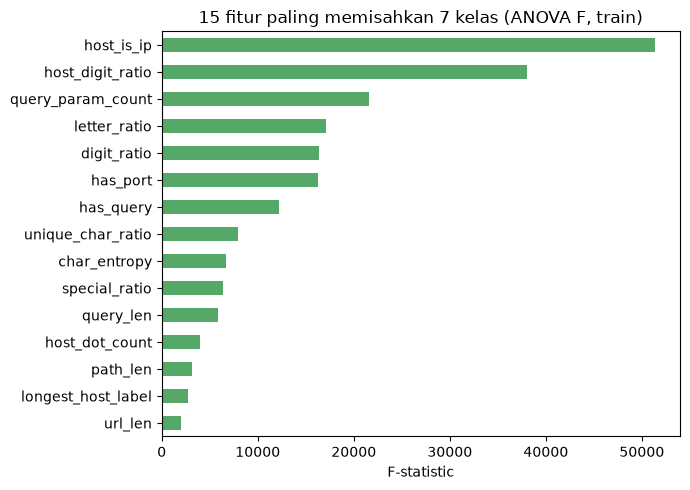

In [8]:
from sklearn.feature_selection import f_classif

f_stat, p_val = f_classif(Xtr, y_train)   # dihitung hanya pada train
imp = (pd.Series(np.nan_to_num(f_stat, nan=0.0), index=NAMA_FITUR)
       .sort_values(ascending=False))
display(imp.head(15).round(2).to_frame("F-statistic"))

fig, ax = plt.subplots(figsize=(7, 5))
imp.head(15).sort_values().plot.barh(ax=ax, color="#55a868")
ax.set(title="15 fitur paling memisahkan 7 kelas (ANOVA F, train)",
       xlabel="F-statistic")
plt.tight_layout()
plt.show()

## 8. Simpan hasil

Hasil diringkas ke JSON (konfigurasi + daftar fitur + skor + hasil sweep + fitur
terpenting) dan prediksi per baris disimpan ke CSV terkompresi, supaya eksperimen
bisa diaudit dan dibandingkan dengan 01_VP tanpa menjalankan ulang.

In [9]:
ringkasan = {
    "notebook": "02_KNN_Feature_Engginering_VP",
    "desain": "eksperimen pribadi dari nol (data penuh, 37 fitur buatan sendiri, split acak stratified 70/15/15)",
    "seed": SEED,
    "jumlah_baris_bersih": int(len(feat_df)),
    "jumlah_fitur": len(NAMA_FITUR),
    "nama_fitur": NAMA_FITUR,
    "scaler": repr(scaler),
    "metric": METRIC,
    "split_rows": {"train": int(len(y_train)),
                   "validation": int(len(y_val)),
                   "test": int(len(y_test))},
    "k_candidates": K_CANDIDATES,
    "k_terbaik": K_TERBAIK,
    "knn": repr(model_final),
    "sweep_validation": hasil_sweep,
    "test_metrics": {k: float(v) for k, v in skor.items()},
    "fitur_top15": {k: float(v) for k, v in imp.head(15).items()},
    "versi_paket": versi,
}
(RESULTS_DIR / "knn_fe_vp_metrics.json").write_text(
    json.dumps(ringkasan, indent=2, ensure_ascii=False), encoding="utf-8")

pd.DataFrame({"y_true": y_test, "y_pred": y_pred}).to_csv(
    RESULTS_DIR / "knn_fe_vp_test_predictions.csv.gz",
    index=False, compression="gzip")
print("Hasil tersimpan di:", RESULTS_DIR.resolve())

Hasil tersimpan di: D:\Semester5\ML\244107020017_Machine_Learning\PBL\Exsperimen\results_vp


### Interpretasi hasil akhir

**Sel interpretasi:** merangkum hasil dalam format siap kutip untuk laporan — label
model + representasi, accuracy test, macro F1, kelas dengan F1 terendah, dan batas
keberlakuan desain. Sel ini **membaca file hasil yang sudah tersimpan** di
`results_vp/`, sehingga bisa dijalankan kapan saja tanpa mengulang training.

In [10]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display
from sklearn.metrics import f1_score

hasil = json.loads(Path("results_vp/knn_fe_vp_metrics.json").read_text(encoding="utf-8"))
pred = pd.read_csv("results_vp/knn_fe_vp_test_predictions.csv.gz")

label_model = f"KNN (k={hasil['k_terbaik']}, {hasil['metric']})"
label_rep = f"{hasil['jumlah_fitur']} fitur numerik URL buatan sendiri + StandardScaler"
kelas = sorted(pred.y_true.unique())
f1_kelas = pd.Series(
    f1_score(pred.y_true, pred.y_pred, labels=kelas, average=None, zero_division=0),
    index=kelas,
).sort_values()
terendah = f1_kelas.index[0]

print(f"{label_model} + {label_rep}:")
print(f"Accuracy test {hasil['test_metrics']['accuracy']:.2%}; macro F1 {hasil['test_metrics']['macro_f1']:.4f}.")
print(f"Kelas dengan F1 terendah: {terendah} ({f1_kelas.iloc[0]:.4f}).")
print("Model dilatih pada seluruh train; validation dan test hanya untuk evaluasi (k dipilih dari validation, bukan test).")
print("Hasil berlaku pada desain VP ini: split acak stratified 70/15/15 atas data penuh (bukan domain-disjoint);")
print("data tidak memuat timestamp, source, atau campaign.")
display(f1_kelas.to_frame("F1 per kelas").round(4))

KNN (k=5, euclidean) + 37 fitur numerik URL buatan sendiri + StandardScaler:
Accuracy test 79.56%; macro F1 0.6217.
Kelas dengan F1 terendah: legitimate (0.1335).
Model dilatih pada seluruh train; validation dan test hanya untuk evaluasi (k dipilih dari validation, bukan test).
Hasil berlaku pada desain VP ini: split acak stratified 70/15/15 atas data penuh (bukan domain-disjoint);
data tidak memuat timestamp, source, atau campaign.


,F1 per kelas
legitimate,0.1335
spam,0.3249
exploit,0.6667
phishing,0.7214
defacement,0.7971
benign,0.8376
malware,0.8705


## 9. Kesimpulan dan limitasi versi VP Feature Engineering

**Ringkasan alur:** data dibersihkan (kosong/konflik/duplikat dibuang) → ekstraksi
**37 fitur deterministik** pada seluruh **783.702 baris** → split acak stratified
70/15/15 (partisi identik dengan 01_VP) → StandardScaler (fit hanya di train) →
KNN euclidean distance-weighted, k dipilih di validation → test dinilai sekali
dengan fokus macro F1 → analisis feature importance.

**Limitasi yang disadari (jangan diklaim lebih dari ini):**

1. **Split acak per-baris** — domain yang sama bisa menyeberang partisi; tidak
   apple-to-apple dengan protokol domain-disjoint kelompok.
2. **37 fitur adalah rancangan manusia** — pola yang tidak terpikirkan tidak akan
   tertangkap (berbeda dari TF-IDF yang bisa menemukan pola tak terduga). Hasil
   importance hanya mencerminkan kualitas rancangan fitur ini.
3. **Euclidean dipilih di depan**, belum diadu dengan cosine di validation
   (itu eksperimen lanjutan yang sah — pakai knob `METRIC`).
4. **Kelas `exploit` tetap sangat langka** (243 baris dari 783 ribu); skor kelas
   itu indikasi kasar, bukan kesimpulan.

**Ide lanjutan:** bandingkan macro F1 notebook ini dengan `01_KNN_TFIDF_VP`
(data & partisi sama, model sama — yang berbeda hanya representasinya); coba
`METRIC = "cosine"`; tambah/kurangi fitur berdasarkan hasil importance; atau gabung
kedua filosofi (fitur struktur + TF-IDF dalam satu vektor).